In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.signal import savgol_filter
from sklearn.decomposition import FastICA
import padasip as pa
import IPython.display as ipd

matplotlib.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

from setup_dsp import *


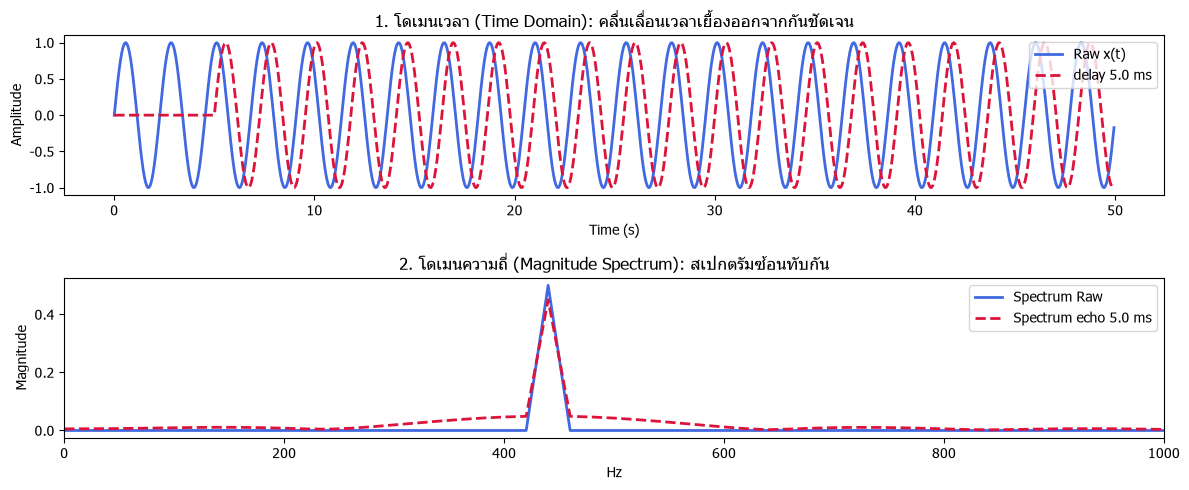

In [2]:
fs = 16000           
duration = 0.05
t = time_axis(fs, duration)
raw = generate_sine(440,t)
echo = generate_sine(440,t)
delay_ms = 5.0
delay_samples = int(fs * delay_ms / 1000.0)
echo = np.zeros_like(raw)
echo[delay_samples:] = raw[:-delay_samples]

N = len(raw)
freqs = np.fft.rfftfreq(N, d=1/fs)
mag_raw = np.abs(np.fft.rfft(raw)) / N
mag_echo = np.abs(np.fft.rfft(echo)) / N


plt.figure(figsize=(12,5))
plt.subplot(2,1,1)
plt.plot(t * 1000,raw, label="Raw x(t)", color="royalblue", lw=2)
plt.plot(t * 1000, echo, label=f"delay {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("1. โดเมนเวลา (Time Domain): คลื่นเลื่อนเวลาเยื้องออกจากกันชัดเจน")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.tight_layout()

plt.subplot(2,1,2)
plt.plot(freqs, mag_raw, label="Spectrum Raw", color="royalblue", lw=2)
plt.plot(freqs, mag_echo, label=f"Spectrum echo {delay_ms} ms", color="crimson", lw=2, linestyle="--")
plt.title("2. โดเมนความถี่ (Magnitude Spectrum): สเปกตรัมซ้อนทับกัน")
plt.xlabel("Hz")
plt.ylabel("Magnitude")
plt.legend(loc="upper right")
plt.xlim(0, 1000)
plt.tight_layout()


[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 5.00 ms (80 samples)
[Echo Lag] โหมด: กำหนดค่าเอง (Custom) -> ใช้ Lag = 12.00 ms (192 samples)


🎯 กรณีที่ 1: กำหนด Echo Lag = 5 ms (80 samples)
   -> จุดที่ตรวจพบ: Lag = 80 จุด (5.00 ms)


🎯 กรณีที่ 2: กำหนด Echo Lag = 12 ms (192 samples)
   -> จุดที่ตรวจพบ: Lag = 192 จุด (12.00 ms)


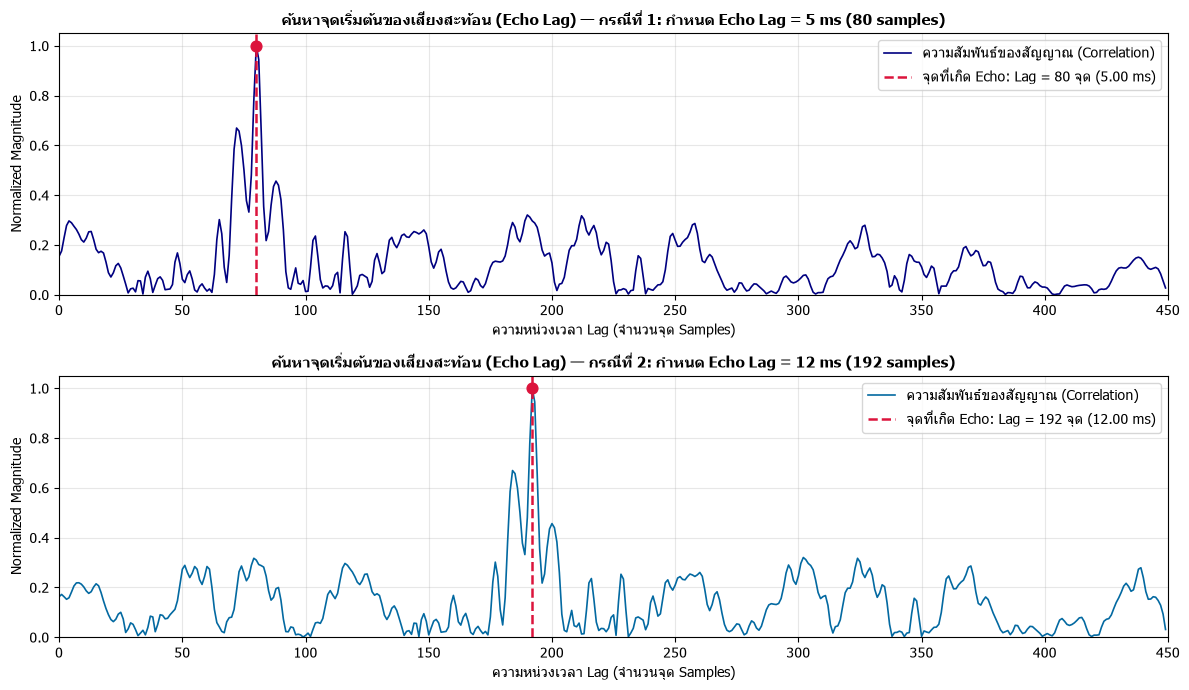

In [3]:
# ==============================================================================
# ค้นหาจุดเริ่มต้นของเสียงสะท้อน (Echo Lag) เปรียบเทียบ 2 กรณี: 5 ms และ 12 ms
# ==============================================================================
# 1. โหลดข้อมูลทั้ง 2 กรณี (Lag = 5 ms และ Lag = 12 ms)
t1, raw1, echo1, fs = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=5.0)
t2, raw2, echo2, _ = get_scenario_audio(scenario=1, clip_idx1=0, reverb_level=1, lag_ms=12.0)

test_cases = [
    {"title": "กรณีที่ 1: กำหนด Echo Lag = 5 ms (80 samples)", "raw": raw1, "echo": echo1, "color": "navy", "accent": "crimson"},
    {"title": "กรณีที่ 2: กำหนด Echo Lag = 12 ms (192 samples)", "raw": raw2, "echo": echo2, "color": "#0369a1", "accent": "crimson"},
]

plt.figure(figsize=(12, 7))

for idx, case in enumerate(test_cases, 1):
    raw_sig = case["raw"]
    echo_sig = case["echo"]
    
    # คำนวณ Cross-Correlation ช่วง 1 วินาทีแรก
    seg_len = fs * 1
    corr = np.correlate(echo_sig[:seg_len], raw_sig[:seg_len], mode="full")
    lags = np.arange(-seg_len + 1, seg_len)
    max_lag_show = 450
    zero_idx = seg_len - 1
    
    # ตัดมาเฉพาะช่วง Lag 0 ถึง 450 จุด และทำเป็นค่าความแรง Normalized (0 ถึง 1)
    lags_view = lags[zero_idx : zero_idx + max_lag_show]
    corr_view = np.abs(corr[zero_idx : zero_idx + max_lag_show])
    corr_view = corr_view / np.max(corr_view)
    
    # ค้นหาจุดที่เกิด Echo แรงที่สุดอัตโนมัติด้วย np.argmax
    detected_lag = lags_view[np.argmax(corr_view)]
    detected_ms = detected_lag / fs * 1000.0
    
    print(f"🎯 {case['title']}")
    print(f"   -> จุดที่ตรวจพบ: Lag = {detected_lag} จุด ({detected_ms:.2f} ms)")
    
    # พล็อตกราฟ Subplot
    plt.subplot(2, 1, idx)
    plt.plot(lags_view, corr_view, color=case["color"], linewidth=1.2, label="ความสัมพันธ์ของสัญญาณ (Correlation)")
    plt.axvline(detected_lag, color=case["accent"], linestyle="--", linewidth=1.8,
                label=f"จุดที่เกิด Echo: Lag = {detected_lag} จุด ({detected_ms:.2f} ms)")
    plt.scatter([detected_lag], [1.0], color=case["accent"], s=60, zorder=5)
    
    plt.title(f"ค้นหาจุดเริ่มต้นของเสียงสะท้อน (Echo Lag) — {case['title']}", fontsize=11, fontweight="bold")
    plt.xlabel("ความหน่วงเวลา Lag (จำนวนจุด Samples)")
    plt.ylabel("Normalized Magnitude")
    plt.xlim(0, max_lag_show)
    plt.ylim(0, 1.05)
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
